# Predicción de ROP — Pozos de Noruega
## Modelado y comparación de algoritmos de regresión

**Variable target:** `Rate of Penetration m/h` (ROP)  
**Datasets:** `conjunto_limpio_balanceado.csv` (8.473 filas) y `conjunto_limpio.csv` (34.456 filas)  
**Estrategia de validación:** Leave-One-Well-Out (LOWO) + holdout final en Pozo 5

---

### Modelos evaluados
| # | Modelo | Tipo |
|---|---|---|
| 1 | Linear Regression | Baseline lineal |
| 2 | Ridge Regression | Lineal regularizado (maneja multicolinealidad MD/TVD) |
| 3 | Random Forest | Ensemble, captura no-linealidades |
| 4 | XGBoost | Gradient boosting, generalmente mejor en datos tabulares |
| 5 | MLP (Red neuronal) | Referencia de arquitectura más compleja |

Partimos de los análisis anteriores de los pozos 0, 1, 2, 3, 4, 5 y 6, donde terminamos obteniendo un dataset limpio para el entrenamiento de modelos de regresión. A partir de dichos análisis se obtuvieron dos archivos CSV principales: uno balanceado con 8.473 filas y otro que, si bien tiene una limpieza previa, es mayor, con 34.456 filas. La diferencia radica en que para el dataset de menor cantidad de filas se tuvo en cuenta cómo los sensores tomaron datos sobre la profundidad de cada pozo y, a partir de ello, se igualó a una misma unidad de medida para poder unificar balanceadamente los datasets mencionados al principio.

In [28]:
# Instalar XGBoost si no está disponible
!pip install xgboost --quiet

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

SEED = 42
TARGET = 'Rate of Penetration m/h'
POZO_TEST = 5
POZOS = [0, 1, 2, 3, 4, 6]

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11
print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


## 1. Carga de datos

Los archivos fueron generados por el notebook `ROP_Noruega_Resto_Pozos_Entrenamiento_Sin_Relleno.ipynb`.  
Montar Google Drive y ajustar la ruta si es necesario.

In [ ]:
import os
# Si los CSV están en la carpeta actual usa ruta local; si no, ajustar la ruta (ej. Google Drive)
RUTA_BASE = '' if os.path.exists('conjunto_limpio_balanceado.csv') else '/home/valentin/Escritorio/ypf/YPF-rop-predictor/'

bal  = pd.read_csv(RUTA_BASE + 'conjunto_limpio_balanceado.csv')
full = pd.read_csv(RUTA_BASE + 'conjunto_limpio.csv')
test_p5 = pd.read_csv(RUTA_BASE + 'USROP_A 5 sin relleno.csv')

print(f'Balanceado:  {bal.shape[0]:,} filas × {bal.shape[1]} columnas')
print(f'Completo:    {full.shape[0]:,} filas × {full.shape[1]} columnas')
print(f'Test (P5):   {test_p5.shape[0]:,} filas × {test_p5.shape[1]} columnas')
bal.head()

Balanceado:  8,473 filas × 11 columnas
Completo:    34,456 filas × 11 columnas
Test (P5):   908 filas × 10 columnas


,Measured Depth m,Weight on Bit kkgf,Average Standpipe Pressure kPa,Average Surface Torque kN.m,Rate of Penetration m/h,Average Rotary Speed rpm,Mud Flow In L/min,Diameter mm,Average Hookload kkgf,Hole Depth (TVD) m,pozo
0,489.509,6.164320,9521.246136,0.352513,41.897808,84.0,2784.321942,311.15,94.111345,489.252768,0
1,490.118,6.431940,9319.919223,0.284722,43.671744,84.0,2784.321942,311.15,94.124953,489.855967,0
2,491.033,5.842270,9440.922214,0.244047,42.864024,84.0,2784.321942,311.15,93.780222,490.760309,0
3,492.100,6.023707,9279.998579,0.013558,41.675304,84.0,2784.321942,311.15,93.934444,491.815222,0
4,493.166,4.354487,9242.766889,0.000000,33.204912,84.0,2784.321942,311.15,95.993753,492.869830,0


## 2. EDA rápido del dataset balanceado

Revisamos distribución del target y composición del dataset antes de modelar.

In [ ]:
print('Tipos de columnas:')
print(bal.dtypes)
print('\nNulos por columna:')
print(bal.isna().sum())
print('\nFilas por pozo:')
print(bal['pozo'].value_counts().sort_index())

Tipos de columnas:
Measured Depth m                  float64
Weight on Bit kkgf                float64
Average Standpipe Pressure kPa    float64
Average Surface Torque kN.m       float64
Rate of Penetration m/h           float64
Average Rotary Speed rpm          float64
Mud Flow In L/min                 float64
Diameter mm                       float64
Average Hookload kkgf             float64
Hole Depth (TVD) m                float64
pozo                                int64
dtype: object

Nulos por columna:
Measured Depth m                  0
Weight on Bit kkgf                0
Average Standpipe Pressure kPa    0
Average Surface Torque kN.m       0
Rate of Penetration m/h           0
Average Rotary Speed rpm          0
Mud Flow In L/min                 0
Diameter mm                       0
Average Hookload kkgf             0
Hole Depth (TVD) m                0
pozo                              0
dtype: int64

Filas por pozo:
pozo
0     603
1     554
2    1979
3    2518
4    2451
6   

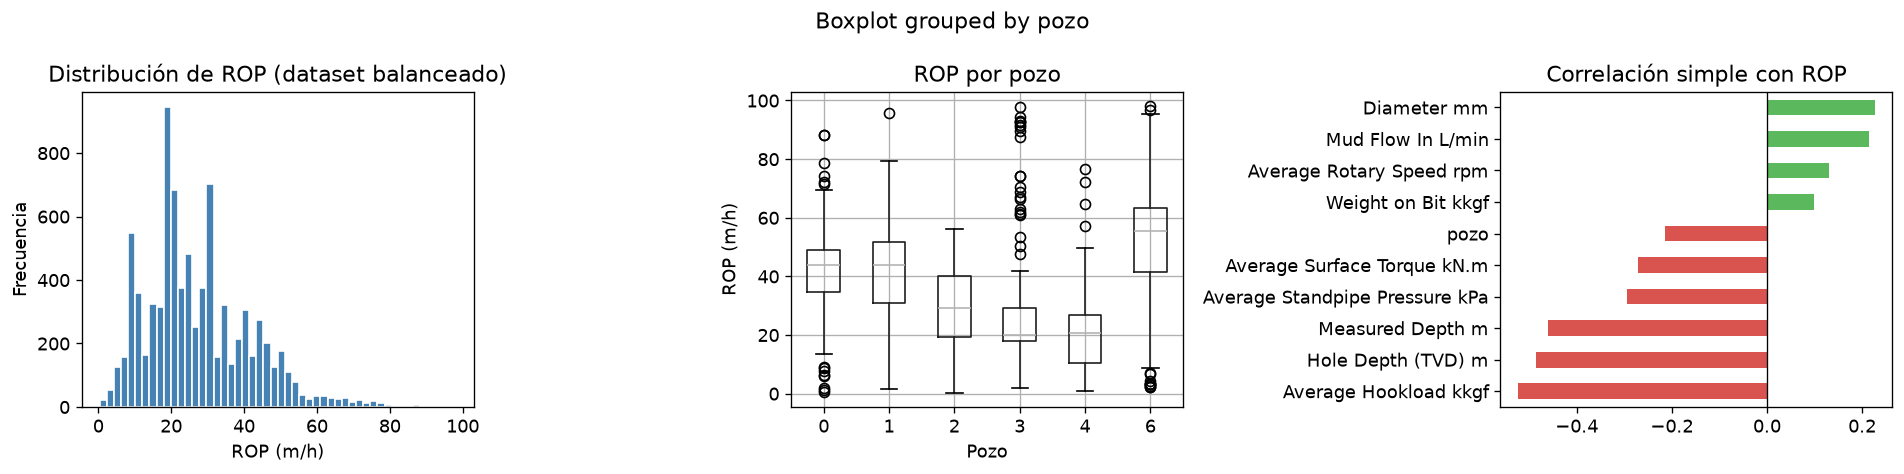

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Distribución del target
axes[0].hist(bal[TARGET], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Distribución de ROP (dataset balanceado)')
axes[0].set_xlabel('ROP (m/h)')
axes[0].set_ylabel('Frecuencia')

# ROP por pozo (boxplot)
bal.boxplot(column=TARGET, by='pozo', ax=axes[1])
axes[1].set_title('ROP por pozo')
axes[1].set_xlabel('Pozo')
axes[1].set_ylabel('ROP (m/h)')
plt.sca(axes[1]); plt.title('ROP por pozo')

# Correlación con ROP
features_num = bal.select_dtypes(include='number').drop(columns=[TARGET])
corr = features_num.corrwith(bal[TARGET]).sort_values()
corr.plot(kind='barh', ax=axes[2], color=['#d9534f' if v < 0 else '#5cb85c' for v in corr])
axes[2].set_title('Correlación simple con ROP')
axes[2].axvline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()

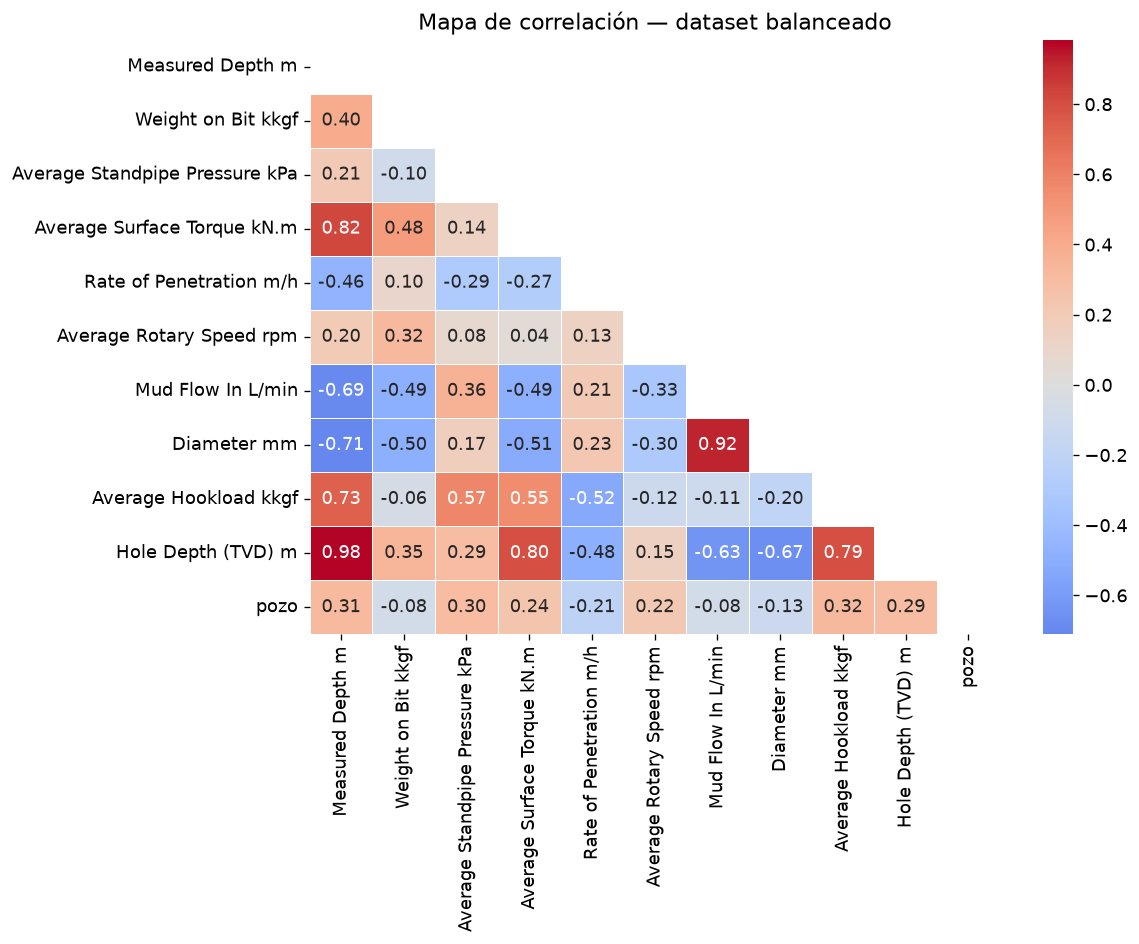


Nota: Measured Depth m y Hole Depth (TVD) m tienen alta multicolinealidad (VIF > 50).
Se elimina TVD del set de features para el entrenamiento.


In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
corr_matrix = bal.select_dtypes(include='number').corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, linewidths=0.5)
ax.set_title('Mapa de correlación — dataset balanceado')
plt.tight_layout()
plt.show()

print('\nNota: Measured Depth m y Hole Depth (TVD) m tienen alta multicolinealidad (VIF > 50).')
print('Se elimina TVD del set de features para el entrenamiento.')

## 3. Preprocesamiento

Pasos aplicados:
1. Eliminar `Hole Depth (TVD) m` por alta multicolinealidad con `Measured Depth m` (VIF > 50)
2. Separar features (X) y target (y)
3. `pozo` se mantiene como feature numérico (los modelos tree-based lo aprovechan bien)
4. Escala con `RobustScaler` — robusto ante outliers típicos de datos de perforación
5. Split train/test: pozos 0,1,2,3,4,6 = entrenamiento | pozo 5 = holdout final

In [ ]:
def preparar_dataset(df, test_df_externo=None, pozo_test=POZO_TEST, drop_tvd=True):
    """Devuelve X_train, X_test, y_train, y_test ya escalados, más el scaler y features."""
    df = df.copy()

    if drop_tvd and 'Hole Depth (TVD) m' in df.columns:
        df = df.drop(columns=['Hole Depth (TVD) m'])

    train_df = df[df['pozo'] != pozo_test].copy() if 'pozo' in df.columns else df.copy()

    features = [c for c in train_df.columns if c != TARGET]

    X_train = train_df[features].values
    y_train = train_df[TARGET].values

    scaler = RobustScaler()
    X_train_sc = scaler.fit_transform(X_train)

    if test_df_externo is not None:
        test_df = test_df_externo.copy()
        if drop_tvd and 'Hole Depth (TVD) m' in test_df.columns:
            test_df = test_df.drop(columns=['Hole Depth (TVD) m'])
        if 'pozo' in features and 'pozo' not in test_df.columns:
            test_df['pozo'] = pozo_test
        X_test_sc = scaler.transform(test_df[features].values)
        y_test    = test_df[TARGET].values
    else:
        X_test_sc, y_test = None, None

    return X_train_sc, X_test_sc, y_train, y_test, scaler, features


X_train, X_test, y_train, y_test, scaler_bal, features_bal = preparar_dataset(bal, test_df_externo=test_p5)

print(f'Train: {X_train.shape} | Test (pozo 5): {X_test.shape}')
print(f'Features usadas ({len(features_bal)}): {features_bal}')

Train: (8473, 9) | Test (pozo 5): (908, 9)
Features usadas (9): ['Measured Depth m', 'Weight on Bit kkgf', 'Average Standpipe Pressure kPa', 'Average Surface Torque kN.m', 'Average Rotary Speed rpm', 'Mud Flow In L/min', 'Diameter mm', 'Average Hookload kkgf', 'pozo']


## 4. Definición de modelos

Se definen los 5 modelos con hiperparámetros razonables de punto de partida.  
No se hace tuning exhaustivo en esta etapa — el foco es comparar la familia de algoritmos.

In [ ]:
MODELOS = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=SEED
    ),
    'XGBoost': XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        n_jobs=-1,
        random_state=SEED,
        verbosity=0
    ),
    'MLP': MLPRegressor(
        hidden_layer_sizes=(128, 64, 32),
        activation='relu',
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=SEED
    )
}

El split 80/20 no evalúa si el modelo generaliza a pozos nuevos — evalúa si existe una relación estadística aprendible entre los parámetros operativos (WOB, RPM, torque, presión) y el ROP dentro de condiciones conocidas. Un R² alto aquí confirma que esa relación existe y que el modelo la captura.

In [40]:
def get_features(df):
    drop = [TARGET, 'Hole Depth (TVD) m', 'pozo']
    return [c for c in df.columns if c not in drop]

In [41]:
from sklearn.model_selection import train_test_split

feats = get_features(bal)
X = bal[feats].values
y = bal[TARGET].values

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)

print('=== Split aleatorio 80/20 (todas las filas mezcladas) ===')
for nombre, modelo in MODELOS.items():
    pipe = Pipeline([('scaler', RobustScaler()), ('modelo', modelo)])
    pipe.fit(X_tr, y_tr)
    y_pred = pipe.predict(X_te)
    r2   = round(r2_score(y_te, y_pred), 4)
    rmse = round(np.sqrt(mean_squared_error(y_te, y_pred)), 4)
    print(f'{nombre:20s}  R²={r2:7.4f}  RMSE={rmse:.4f}')

=== Split aleatorio 80/20 (todas las filas mezcladas) ===
Linear Regression     R²= 0.3968  RMSE=11.4786
Ridge                 R²= 0.3969  RMSE=11.4778
Random Forest         R²= 0.8586  RMSE=5.5578
XGBoost               R²= 0.8888  RMSE=4.9286
MLP                   R²= 0.7863  RMSE=6.8324


Los resultados muestran una división clara entre modelos lineales y no lineales.

**Modelos lineales (R²≈0.40):** capturan solo el 40% de la varianza del ROP.
La relación entre los parámetros operativos y el ROP no es lineal — duplicar el WOB
no duplica el ROP, existen umbrales, saturaciones e interacciones entre variables que
una recta no puede describir.

**Modelos no lineales (R²=0.79–0.89):** XGBoost logra R²=0.89 con un error promedio
de 4.9 m/h sobre un target que varía entre 0 y 98 m/h. Esto confirma que la combinación
de parámetros operativos contiene suficiente información para estimar el ROP dentro de
condiciones conocidas, y que los modelos basados en árboles capturan las interacciones
no lineales que el análisis univariado del EDA no podía revelar.

> **Conclusión:** la relación entre los parámetros de perforación y el ROP es no lineal
> e interactiva. Dentro de condiciones conocidas, XGBoost la captura con alta precisión.
> Este resultado establece el techo de rendimiento del modelo y confirma que el problema
> es estadísticamente aprendible — la dificultad no está en el algoritmo sino en la
> generalización a pozos nuevos, que se analiza en los experimentos siguientes.

## Hallazgo: heterogeneidad de ROP entre pozos

Antes de evaluar la capacidad de generalización cross-well, analizamos si los pozos
son comparables entre sí. Si los pozos tienen distribuciones de ROP muy distintas,
un modelo entrenado en pozos "rápidos" va a sobreestimar sistemáticamente los pozos
"lentos" sin importar qué algoritmo se use — el problema no sería el modelo sino los datos.

Los gráficos siguientes muestran la distribución de ROP por pozo en escala original
y luego con normalización Z-score (media=0, desvío=1). La normalización por pozo
permite que el modelo aprenda variaciones relativas dentro de cada pozo en lugar de
valores absolutos, eliminando el efecto del ROP base de cada formación.

Este análisis motiva dos decisiones para los experimentos siguientes:
1. Usar **Leave-One-Well-Out (LOWO)** como estrategia de validación cross-well
2. Evaluar si normalizar el target por pozo antes de entrenar mejora la generalización

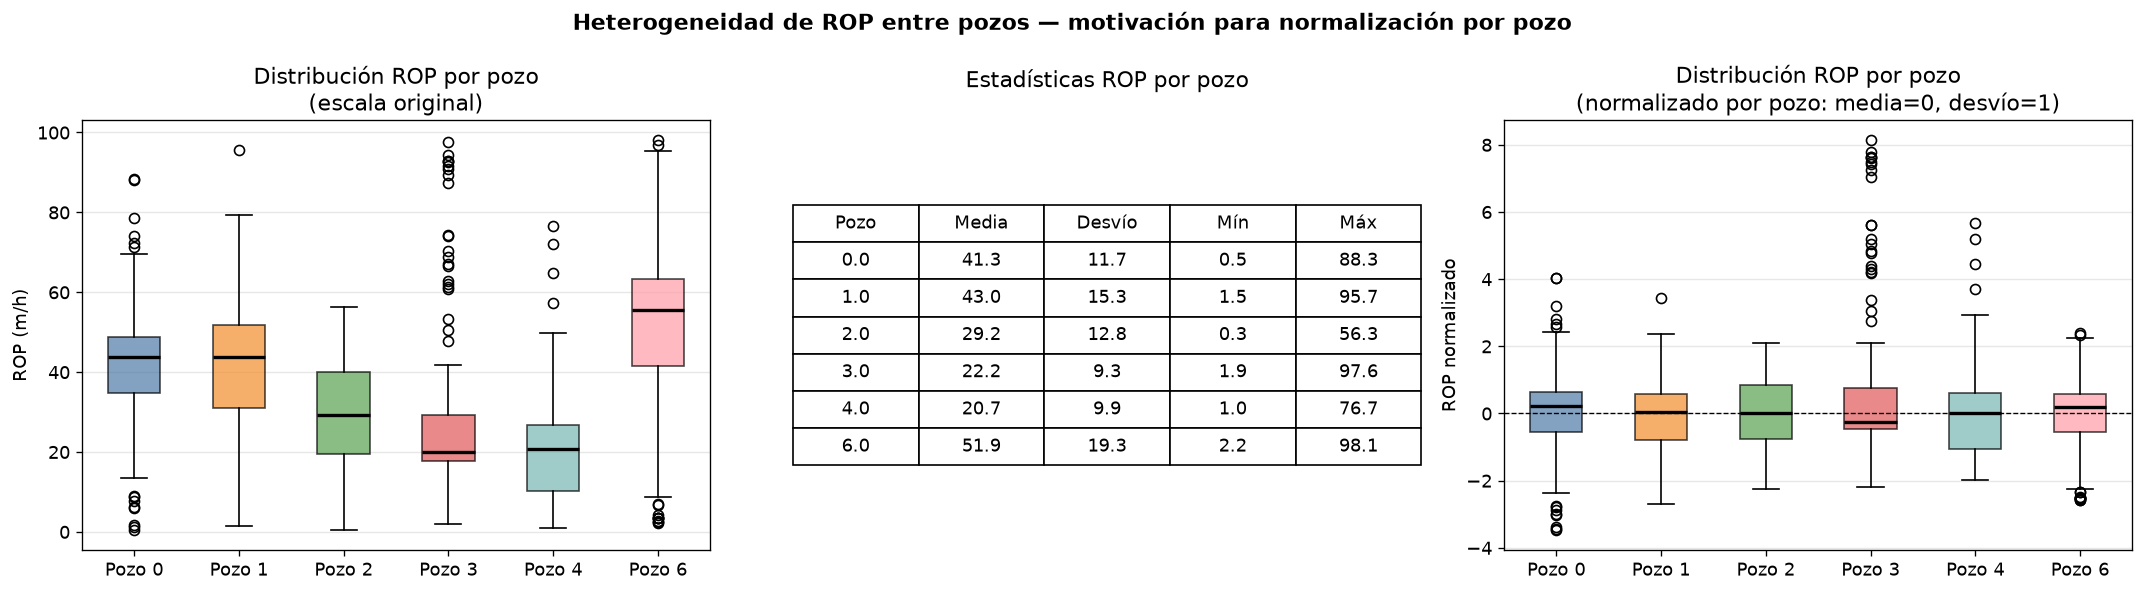

Diferencia entre la media más alta y más baja: 31.2 m/h
Eso representa un 151% de diferencia relativa entre pozos extremos.


In [42]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Boxplot ROP por pozo (escala original) ---
data_por_pozo = [bal[bal['pozo'] == p][TARGET].values for p in POZOS]
bp = axes[0].boxplot(data_por_pozo, patch_artist=True,
                     medianprops={'color': 'black', 'linewidth': 2})
colores = ['#4e79a7','#f28e2b','#59a14f','#e15759','#76b7b2','#ff9da7']
for patch, color in zip(bp['boxes'], colores):
    patch.set_facecolor(color); patch.set_alpha(0.7)
axes[0].set_xticks(range(1, len(POZOS) + 1))
axes[0].set_xticklabels([f'Pozo {p}' for p in POZOS])
axes[0].set_title('Distribución ROP por pozo\n(escala original)')
axes[0].set_ylabel('ROP (m/h)')
axes[0].grid(axis='y', alpha=0.3)

# --- Tabla de estadísticas ---
stats = bal.groupby('pozo')[TARGET].agg(['mean','std','min','max']).round(1)
stats.columns = ['Media', 'Desvío', 'Mín', 'Máx']
axes[1].axis('off')
tabla = axes[1].table(
    cellText=stats.reset_index().values,
    colLabels=['Pozo'] + stats.columns.tolist(),
    cellLoc='center', loc='center'
)
tabla.auto_set_font_size(False)
tabla.set_fontsize(11)
tabla.scale(1, 2)
axes[1].set_title('Estadísticas ROP por pozo', pad=20)

# --- Boxplot ROP normalizado por pozo (media=0, desvío=1) ---
bal_norm = bal.copy()
for p in POZOS:
    mask = bal_norm['pozo'] == p
    media  = bal_norm.loc[mask, TARGET].mean()
    desvio = bal_norm.loc[mask, TARGET].std()
    bal_norm.loc[mask, TARGET] = (bal_norm.loc[mask, TARGET] - media) / desvio

data_norm = [bal_norm[bal_norm['pozo'] == p][TARGET].values for p in POZOS]
bp2 = axes[2].boxplot(data_norm, patch_artist=True,
                      medianprops={'color': 'black', 'linewidth': 2})
for patch, color in zip(bp2['boxes'], colores):
    patch.set_facecolor(color); patch.set_alpha(0.7)
axes[2].set_xticks(range(1, len(POZOS) + 1))
axes[2].set_xticklabels([f'Pozo {p}' for p in POZOS])
axes[2].set_title('Distribución ROP por pozo\n(normalizado por pozo: media=0, desvío=1)')
axes[2].set_ylabel('ROP normalizado')
axes[2].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[2].grid(axis='y', alpha=0.3)

plt.suptitle('Heterogeneidad de ROP entre pozos — motivación para normalización por pozo',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Diferencia entre la media más alta y más baja:',
      round(stats['Media'].max() - stats['Media'].min(), 1), 'm/h')
print(f'Eso representa un {round((stats["Media"].max() / stats["Media"].min() - 1)*100)}%',
      'de diferencia relativa entre pozos extremos.')

## 5. Validación Leave-One-Well-Out (LOWO)

Para cada fold: se entrena con 5 de los 6 pozos de entrenamiento y se valida en el restante.  
Esto mide cuán bien generaliza el modelo a un **pozo no visto**, que es el caso real de uso.  

> El Pozo 5 **no participa** en este paso — se reserva como holdout final.

In [ ]:
def metricas(y_true, y_pred, nombre_modelo='', fold=''):
    r2   = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    return {'modelo': nombre_modelo, 'fold': fold, 'R²': round(r2, 4),
            'RMSE': round(rmse, 4), 'MAE': round(mae, 4)}

def get_features(df):
    drop = [TARGET, 'Hole Depth (TVD) m', 'pozo']
    return [c for c in df.columns if c not in drop]


def lowo_cv(df, modelos, pozo_test=POZO_TEST):
    pozos_train = sorted(df[df['pozo'] != pozo_test]['pozo'].unique())
    resultados = []

    for nombre_modelo, modelo in modelos.items():
        print(f'  Entrenando {nombre_modelo}...')
        for pozo_val in pozos_train:
            pozos_fit = [p for p in pozos_train if p != pozo_val]

            df_fit = df[df['pozo'].isin(pozos_fit)].copy()
            df_val = df[df['pozo'] == pozo_val].copy()

            feats = get_features(df_fit)

            X_fit = df_fit[feats].values
            X_val = df_val[feats].values
            y_fit = df_fit[TARGET].values
            y_val = df_val[TARGET].values

            pipe = Pipeline([('scaler', RobustScaler()), ('modelo', modelo)])
            pipe.fit(X_fit, y_fit)
            y_pred = pipe.predict(X_val)

            resultados.append(metricas(y_val, y_pred, nombre_modelo, f'Pozo {pozo_val}'))

    return pd.DataFrame(resultados)


print('Corriendo Leave-One-Well-Out CV en dataset BALANCEADO...')
lowo_bal = lowo_cv(bal, MODELOS)
print('\nListo.')

Corriendo Leave-One-Well-Out CV en dataset BALANCEADO...
  Entrenando Linear Regression...
  Entrenando Ridge...
  Entrenando Random Forest...
  Entrenando XGBoost...
  Entrenando MLP...

Listo.


In [ ]:
# Promedio y std de métricas por modelo
resumen_lowo = (
    lowo_bal
    .groupby('modelo')[['R²', 'RMSE', 'MAE']]
    .agg(['mean', 'std'])
    .round(4)
)
resumen_lowo.columns = ['R² medio', 'R² std', 'RMSE medio', 'RMSE std', 'MAE medio', 'MAE std']
resumen_lowo = resumen_lowo.sort_values('R² medio', ascending=False)

print('=== LOWO CV — Dataset Balanceado ===')
display(resumen_lowo)

=== LOWO CV — Dataset Balanceado ===


,R² medio,R² std,RMSE medio,RMSE std,MAE medio,MAE std
modelo,,,,,,
XGBoost,-0.4132,0.4622,14.9910,3.2851,11.8944,2.7175
Ridge,-0.5316,0.7662,15.2228,3.3959,12.4644,3.4715
Linear Regression,-0.5380,0.7749,15.2438,3.3945,12.4879,3.4716
Random Forest,-0.8461,0.7738,16.8333,3.7085,13.7163,3.1335
MLP,-2.1280,1.8894,20.5269,2.2794,16.6719,2.0842


Todos los modelos obtienen R² negativo, lo que significa que predicen **peor que usar
simplemente la media del target**. Esto contrasta drásticamente con el R²=0.89 del
experimento anterior.

El alto desvío estándar del R² (hasta 1.89 en MLP) indica que el rendimiento varía
mucho según el pozo de validación — algunos folds funcionan mejor que otros.
Esto sugiere que el problema no es uniforme: ciertos pozos son sistemáticamente
más difíciles de predecir que otros.

En la siguiente sección analizamos qué pozos específicamente fallan y por qué.

In [ ]:
# Comparativa de ROP por pozo para determinar diferencias entre ellos.

pivot = lowo_bal.pivot(index='fold', columns='modelo', values='R²')
print(pivot.round(3))
print('\nROP estadísticas por pozo:')
print(bal.groupby('pozo')[TARGET].describe()[['min','mean','max','std']].round(1))

modelo  Linear Regression    MLP  Random Forest  Ridge  XGBoost
fold                                                           
Pozo 0              0.130 -2.944         -1.489  0.130   -0.536
Pozo 1              0.095 -0.898         -0.388  0.094   -0.026
Pozo 2             -0.602 -0.775         -1.793 -0.595   -0.949
Pozo 3             -1.947 -4.925         -1.278 -1.925   -0.950
Pozo 4             -0.726 -3.270         -0.246 -0.716   -0.039
Pozo 6             -0.177  0.044          0.117 -0.177    0.021

ROP estadísticas por pozo:
      min  mean   max   std
pozo                       
0     0.5  41.3  88.3  11.7
1     1.5  43.0  95.7  15.3
2     0.3  29.2  56.3  12.8
3     1.9  22.2  97.6   9.3
4     1.0  20.7  76.7   9.9
6     2.2  51.9  98.1  19.3


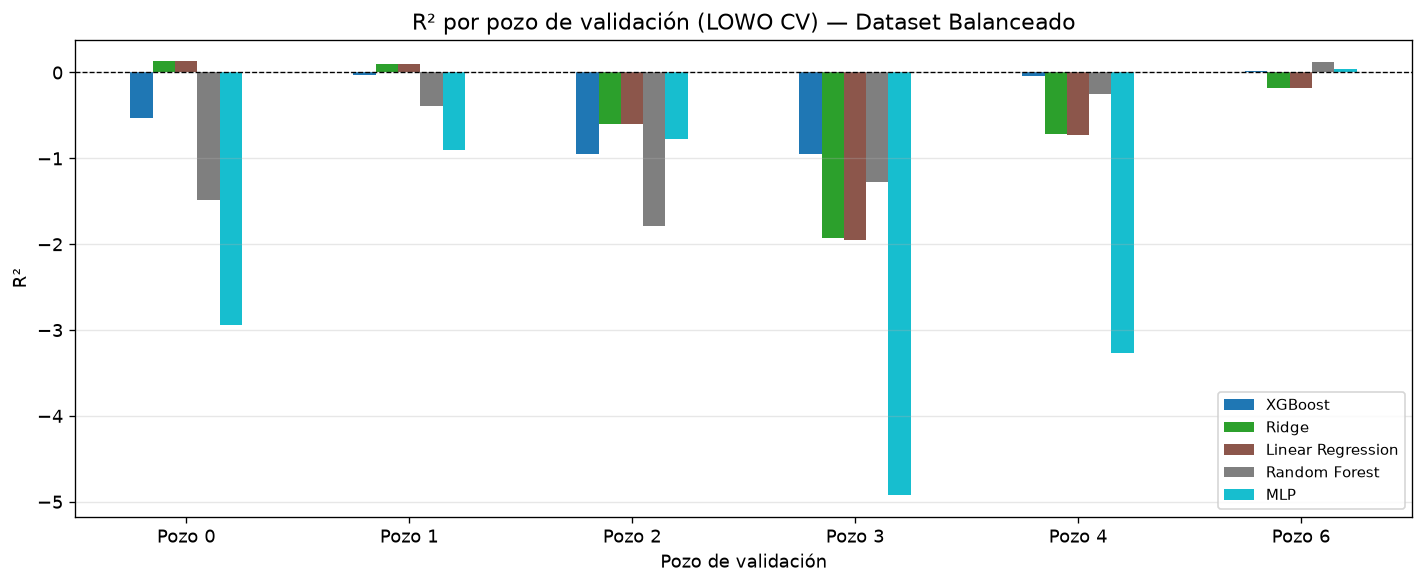


Tabla completa R² por pozo:


modelo,XGBoost,Ridge,Linear Regression,Random Forest,MLP
fold,,,,,
Pozo 0,-0.5358,0.1298,0.1299,-1.4891,-2.9437
Pozo 1,-0.0264,0.0945,0.0947,-0.3880,-0.8984
Pozo 2,-0.9489,-0.5954,-0.6017,-1.7930,-0.7750
Pozo 3,-0.9498,-1.9252,-1.9472,-1.2778,-4.9249
Pozo 4,-0.0388,-0.7162,-0.7264,-0.2457,-3.2698
Pozo 6,0.0206,-0.1773,-0.1771,0.1169,0.0435


In [ ]:
# R² desglosado por pozo de validación para detectar pozos difíciles
pivot_r2 = lowo_bal.pivot(index='fold', columns='modelo', values='R²')
orden_modelos = resumen_lowo.index.tolist()
pivot_r2 = pivot_r2[orden_modelos]  # ordenar columnas

fig, ax = plt.subplots(figsize=(12, 5))
pivot_r2.plot(kind='bar', ax=ax, colormap='tab10')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('R² por pozo de validación (LOWO CV) — Dataset Balanceado')
ax.set_xlabel('Pozo de validación')
ax.set_ylabel('R²')
ax.legend(loc='lower right', fontsize=9)
ax.set_xticklabels(pivot_r2.index, rotation=0)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print('\nTabla completa R² por pozo:')
display(pivot_r2.round(4))

### Conexión con la heterogeneidad de ROP

Los pozos con peor R² (Pozo 3 y Pozo 4) son exactamente los que tienen
la media de ROP más baja del conjunto (22.2 y 20.7 m/h respectivamente),
mientras que los pozos de entrenamiento tienen medias de hasta 51.9 m/h.

El modelo entrena en un contexto de ROP "alto" y cuando predice un pozo
con ROP base "bajo" sobreestima sistemáticamente. El problema no está
en el algoritmo — está en que el target tiene escalas distintas entre pozos.

Esto motiva el siguiente experimento: normalizar el ROP por pozo antes
de entrenar para eliminar ese efecto de escala.

In [ ]:
def lowo_cv_normalizado(df, modelos, pozo_test=POZO_TEST):
    pozos_train = sorted(df[df['pozo'] != pozo_test]['pozo'].unique())
    resultados  = []

    for nombre_modelo, modelo in modelos.items():
        print(f'  Entrenando {nombre_modelo}...')
        for pozo_val in pozos_train:
            pozos_fit = [p for p in pozos_train if p != pozo_val]

            df_fit = df[df['pozo'].isin(pozos_fit)].copy()
            df_val = df[df['pozo'] == pozo_val].copy()

            # Z-score por pozo sobre el target
            stats_fit = df_fit.groupby('pozo')[TARGET].agg(['mean', 'std'])
            for p in pozos_fit:
                mask = df_fit['pozo'] == p
                df_fit.loc[mask, TARGET] = (df_fit.loc[mask, TARGET] - stats_fit.loc[p, 'mean']) / stats_fit.loc[p, 'std']

            # Para el pozo de validación usamos SU propia media y desvío
            media_val = df_val[TARGET].mean()
            desvio_val = df_val[TARGET].std()
            df_val[TARGET] = (df_val[TARGET] - media_val) / desvio_val

            feats = get_features(df_fit)

            X_fit = df_fit[feats].values
            X_val = df_val[feats].values
            y_fit = df_fit[TARGET].values
            y_val = df_val[TARGET].values

            pipe = Pipeline([('scaler', RobustScaler()), ('modelo', modelo)])
            pipe.fit(X_fit, y_fit)
            y_pred_norm = pipe.predict(X_val)

            # Desnormalizar para calcular métricas en m/h
            y_val_mh  = y_val  * desvio_val + media_val
            y_pred_mh = y_pred_norm * desvio_val + media_val

            resultados.append(metricas(y_val_mh, y_pred_mh, nombre_modelo, f'Pozo {pozo_val}'))

    return pd.DataFrame(resultados)


print('Corriendo LOWO CV normalizado — Dataset BALANCEADO...')
lowo_bal_norm = lowo_cv_normalizado(bal, MODELOS)

resumen_bal_norm = (
    lowo_bal_norm.groupby('modelo')[['R²', 'RMSE', 'MAE']]
    .agg(['mean', 'std']).round(4)
)
resumen_bal_norm.columns = ['R² medio', 'R² std', 'RMSE medio', 'RMSE std', 'MAE medio', 'MAE std']
resumen_bal_norm = resumen_bal_norm.sort_values('R² medio', ascending=False)
display(resumen_bal_norm)

Corriendo LOWO CV normalizado — Dataset BALANCEADO...
  Entrenando Linear Regression...
  Entrenando Ridge...
  Entrenando Random Forest...
  Entrenando XGBoost...
  Entrenando MLP...


,R² medio,R² std,RMSE medio,RMSE std,MAE medio,MAE std
modelo,,,,,,
XGBoost,-0.1938,0.3051,13.8936,3.0005,11.0343,2.6148
Ridge,-0.3536,0.7329,14.2284,2.5660,11.0295,2.2682
Linear Regression,-0.3584,0.7406,14.2450,2.5652,11.0382,2.2814
Random Forest,-0.4497,0.4559,15.4084,4.5147,12.4336,4.0451
MLP,-1.4120,0.8962,19.1817,3.2301,15.1159,3.0499


Eliminar el efecto del ROP base de cada pozo reduce el error sistemático,
pero los R² siguen siendo negativos. Esto confirma que la heterogeneidad
entre pozos no es solo un problema de escala — las relaciones entre las
variables de perforación y el ROP varían entre formaciones de forma que
ninguna normalización del target puede corregir completamente.

## 6. Evaluación final en Pozo 5 (holdout)

Entrenamos cada modelo con **todos** los pozos de entrenamiento (0,1,2,3,4,6) y evaluamos en el Pozo 5.  
Este es el número que reportamos como resultado final del modelo.

In [31]:
def evaluar_holdout(df_train_full, df_test, modelos):
    """Entrena en todo el set de train y evalúa en el pozo test."""
    resultados = []
    predicciones = {}

    if 'Hole Depth (TVD) m' in df_train_full.columns:
        df_train_full = df_train_full.drop(columns=['Hole Depth (TVD) m'])
    if 'Hole Depth (TVD) m' in df_test.columns:
        df_test = df_test.drop(columns=['Hole Depth (TVD) m'])

    # Alinear columnas (el archivo del pozo 5 puede no tener 'pozo')
    feats_train = [c for c in df_train_full.columns if c != TARGET]
    feats_test  = [c for c in df_test.columns if c in feats_train]

    # Si 'pozo' está en train pero no en test, agregar columna con valor del pozo test
    if 'pozo' in feats_train and 'pozo' not in df_test.columns:
        df_test = df_test.copy()
        df_test['pozo'] = POZO_TEST
        feats_test = feats_train  # ahora tiene todas

    X_tr = df_train_full[feats_train].values
    X_te = df_test[feats_test].values
    y_tr = df_train_full[TARGET].values
    y_te = df_test[TARGET].values

    for nombre, modelo in modelos.items():
        print(f'  Entrenando {nombre}...')
        pipe = Pipeline([('scaler', RobustScaler()), ('modelo', modelo)])
        pipe.fit(X_tr, y_tr)
        y_pred = pipe.predict(X_te)
        predicciones[nombre] = y_pred
        resultados.append(metricas(y_te, y_pred, nombre, 'Pozo 5 (holdout)'))

    return pd.DataFrame(resultados), predicciones, y_te


# Separar pozos de entrenamiento del balanceado
bal_train = bal[bal['pozo'] != POZO_TEST].copy()

print('Evaluando en holdout (Pozo 5) — Dataset Balanceado...')
resultados_holdout_bal, preds_bal, y_true_p5 = evaluar_holdout(bal_train, test_p5, MODELOS)

print('\n=== Holdout Pozo 5 — Dataset Balanceado ===')
display(resultados_holdout_bal.sort_values('R²', ascending=False).reset_index(drop=True))

Evaluando en holdout (Pozo 5) — Dataset Balanceado...
  Entrenando Linear Regression...
  Entrenando Ridge...
  Entrenando Random Forest...
  Entrenando XGBoost...
  Entrenando MLP...

=== Holdout Pozo 5 — Dataset Balanceado ===


,modelo,fold,R²,RMSE,MAE
0,XGBoost,Pozo 5 (holdout),-0.1039,16.0020,13.8153
1,Random Forest,Pozo 5 (holdout),-0.3200,17.4983,13.9925
2,Ridge,Pozo 5 (holdout),-0.7967,20.4146,16.9171
3,Linear Regression,Pozo 5 (holdout),-0.7982,20.4235,16.9235
4,MLP,Pozo 5 (holdout),-1.2833,23.0139,18.4979


## Hallazgo principal: memorización vs. generalización

Al evaluar los modelos con dos estrategias distintas se obtienen resultados muy diferentes:

| Estrategia | XGBoost R² | Random Forest R² | Interpretación |
|---|---|---|---|
| Split aleatorio 80/20 | **0.89** | **0.86** | Filas de todos los pozos mezcladas en train y test |
| LOWO (pozo completo como test) | **-0.19** | **-0.45** | El pozo de validación nunca estuvo en entrenamiento |

### ¿Por qué tanta diferencia?

En el **split aleatorio**, filas consecutivas del mismo pozo terminan una en train y otra en test.
El modelo básicamente **interpola** — predice condiciones que ya vio con mínimas variaciones.
Las métricas son buenas, pero el modelo no está generalizando: está recordando.

En el **LOWO**, el modelo tiene que predecir un pozo entero que nunca vio durante el entrenamiento.
Esto expone dos limitaciones reales:

1. **El ROP base de cada pozo depende de la formación geológica** — un pozo en una formación
   blanda perfora inherentemente más rápido que uno en roca dura, independientemente de los
   parámetros operativos. Eso no se aprende de otros pozos.

2. **Las relaciones entre variables no son universales** — el EDA mostró que el Pozo 3 tiene
   correlaciones de signo invertido en presión y caudal respecto al resto. El modelo aprende
   una regla general que ese pozo no sigue.

### Conclusión

El R² alto en split aleatorio **no es un indicador confiable** de la capacidad real del modelo.
El LOWO es la evaluación honesta: mide si el modelo puede transferir conocimiento a un pozo nuevo.

Los resultados indican que los modelos entrenados con este dataset son útiles para
**optimización en tiempo real dentro de pozos conocidos**, pero tienen limitaciones importantes
para la **predicción en pozos nuevos** sin datos previos de esa formación.

> Esta distinción — entre memorizar y generalizar — es uno de los conceptos centrales
> en machine learning y justifica el uso de estrategias de validación rigurosas como el LOWO.

## 7. Predicho vs Real y Distribución de Residuos — Pozo 5

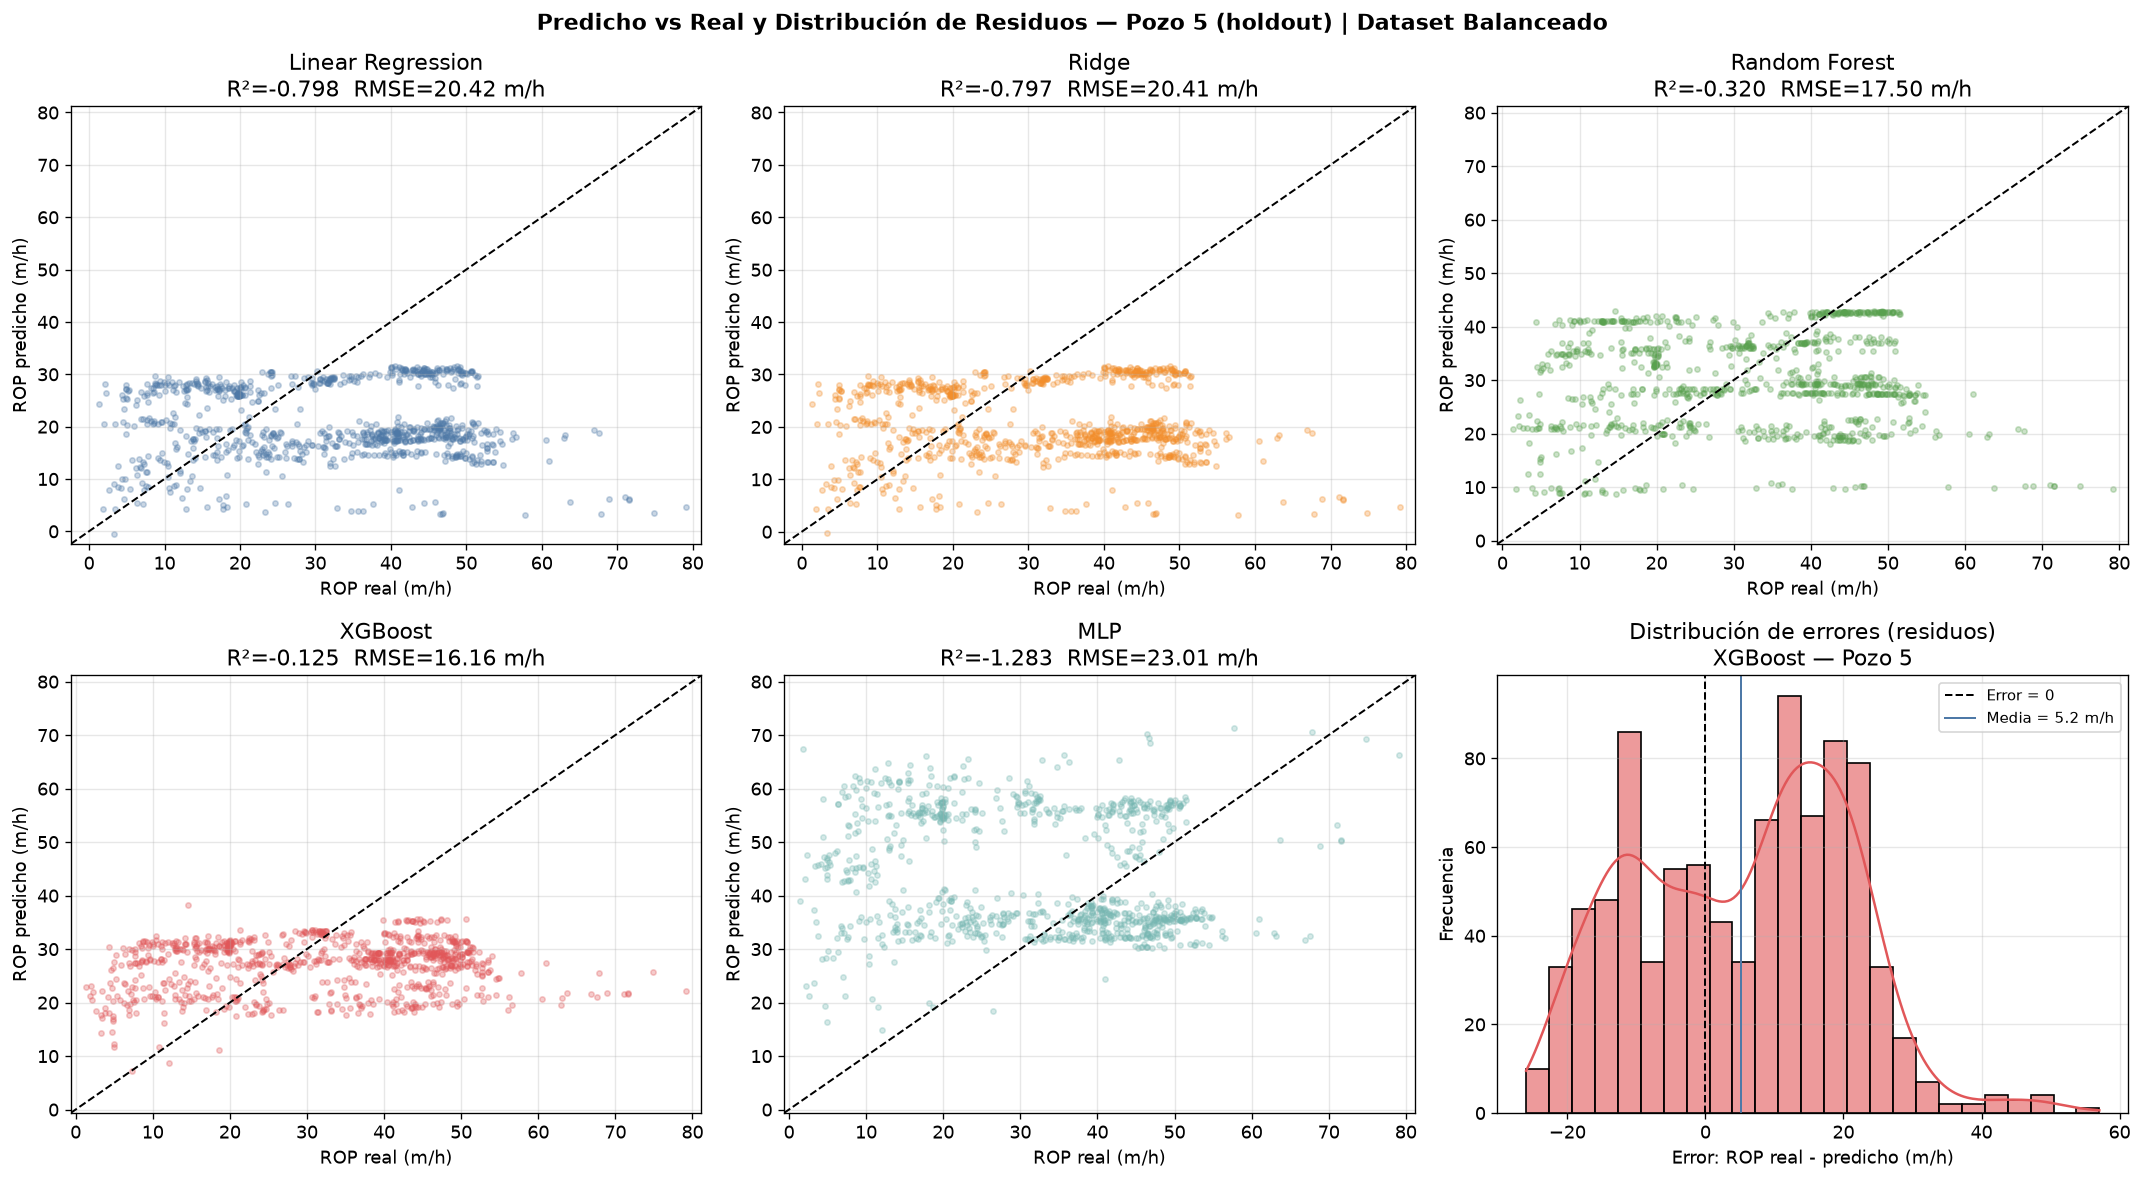

In [32]:
n_mod = len(MODELOS)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
colors = ['#4e79a7', '#f28e2b', '#59a14f', '#e15759', '#76b7b2']

for i, (nombre, y_pred) in enumerate(preds_bal.items()):
    ax = axes[i]
    r2 = r2_score(y_true_p5, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true_p5, y_pred))

    ax.scatter(y_true_p5, y_pred, alpha=0.3, s=10, color=colors[i])
    lim = [min(y_true_p5.min(), y_pred.min()) - 2,
           max(y_true_p5.max(), y_pred.max()) + 2]
    ax.plot(lim, lim, 'k--', linewidth=1.2, label='Ideal')
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f'{nombre}\nR²={r2:.3f}  RMSE={rmse:.2f} m/h')
    ax.set_xlabel('ROP real (m/h)')
    ax.set_ylabel('ROP predicho (m/h)')
    ax.grid(alpha=0.3)

# Histograma de residuos del mejor modelo (XGBoost) en el 6.º subplot
residuos_xgb = y_true_p5 - preds_bal['XGBoost']
sns.histplot(residuos_xgb, bins=25, kde=True, ax=axes[-1], color='#e15759', alpha=0.6)
axes[-1].axvline(0, color='black', linestyle='--', linewidth=1.2, label='Error = 0')
axes[-1].axvline(residuos_xgb.mean(), color='#4e79a7', linestyle='-', linewidth=1.2,
                 label=f'Media = {residuos_xgb.mean():.1f} m/h')
axes[-1].set_title('Distribución de errores (residuos)\nXGBoost — Pozo 5')
axes[-1].set_xlabel('Error: ROP real - predicho (m/h)')
axes[-1].set_ylabel('Frecuencia')
axes[-1].legend(fontsize=9)
axes[-1].grid(alpha=0.3)

plt.suptitle('Predicho vs Real y Distribución de Residuos — Pozo 5 (holdout) | Dataset Balanceado',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Feature Importance — Random Forest y XGBoost

Qué variables son más importantes para predecir ROP según los modelos tree-based.

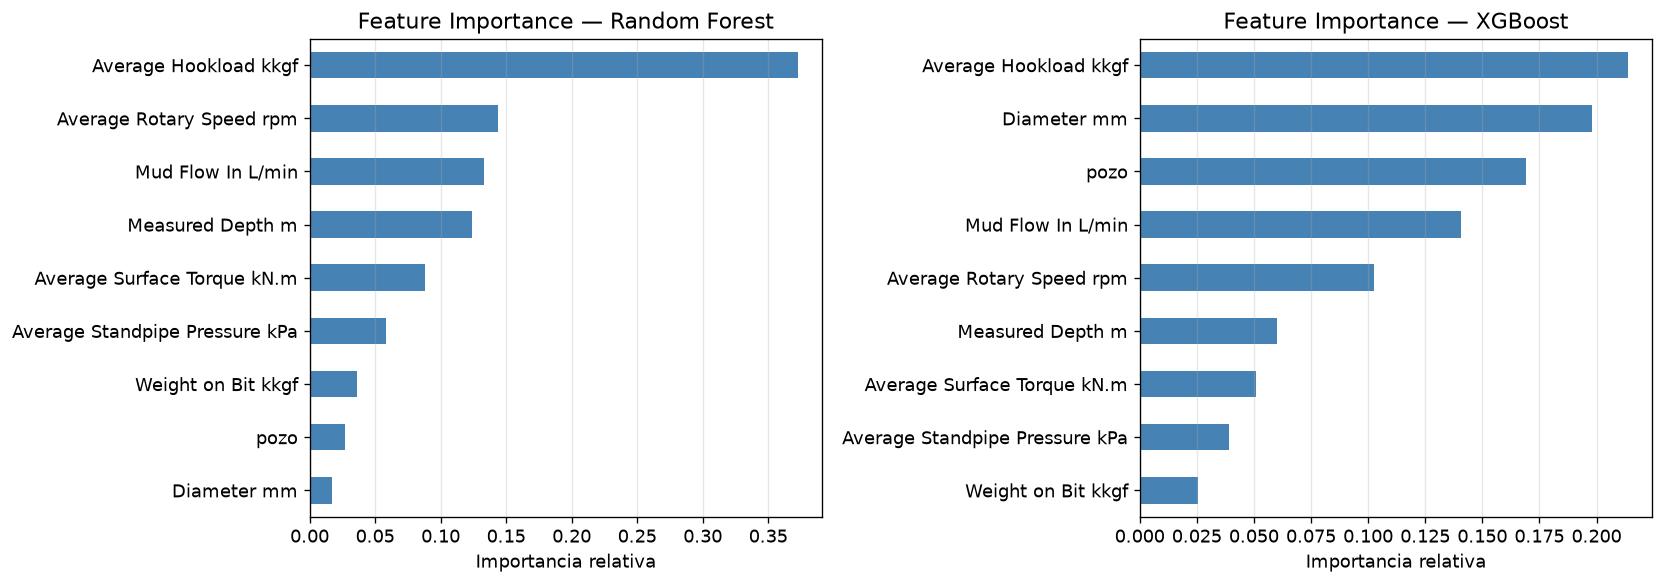

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, nombre in zip(axes, ['Random Forest', 'XGBoost']):
    modelo = MODELOS[nombre]
    importances = pd.Series(modelo.feature_importances_,
                            index=features_bal).sort_values(ascending=True)
    importances.plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title(f'Feature Importance — {nombre}')
    ax.set_xlabel('Importancia relativa')
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Perfil de ROP vs profundidad — Pozo 5

Comparamos la curva de ROP real vs predicha a lo largo de la profundidad medida.  
Esto permite ver si el modelo captura bien las tendencias por tramo de formación.

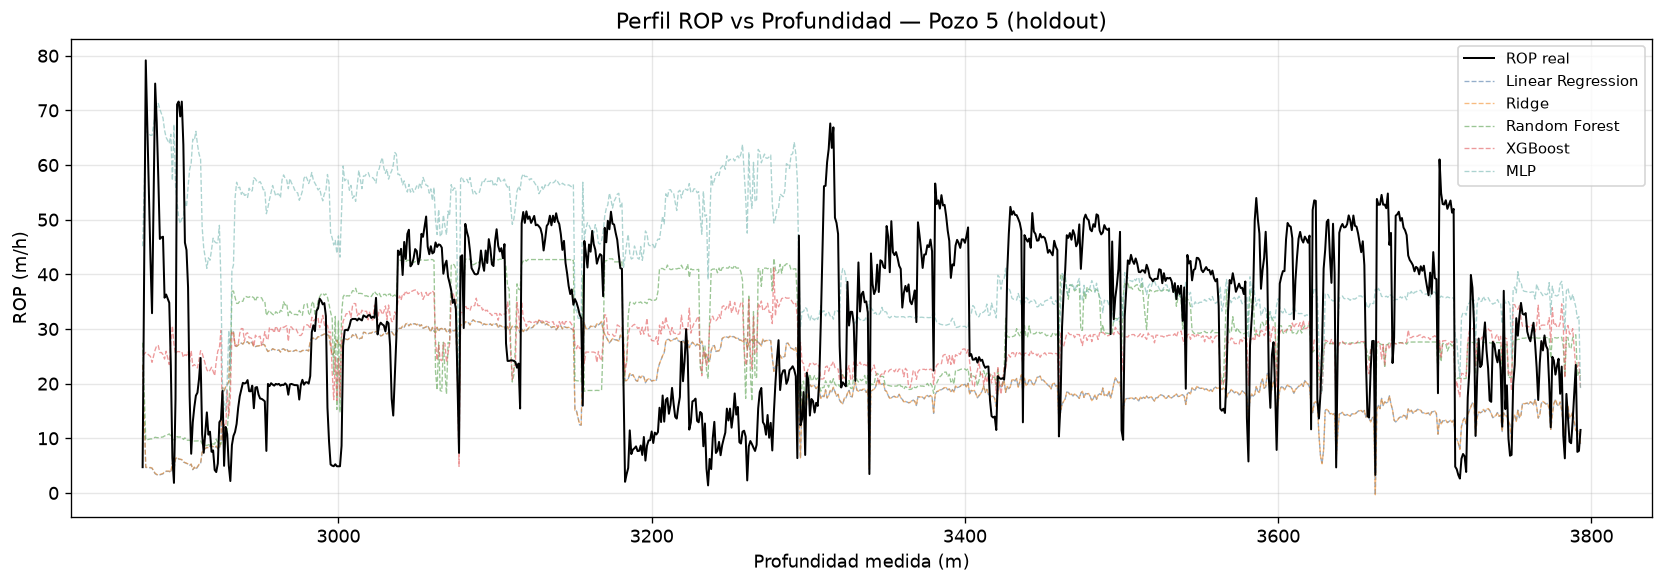

In [34]:
# Obtener columna de profundidad del pozo test
depth_col = 'Measured Depth m'
depth_p5 = test_p5[depth_col].values

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(depth_p5, y_true_p5, color='black', linewidth=1.2, label='ROP real', zorder=5)

colores = ['#4e79a7', '#f28e2b', '#59a14f', '#e15759', '#76b7b2']
for (nombre, y_pred), color in zip(preds_bal.items(), colores):
    ax.plot(depth_p5, y_pred, alpha=0.6, linewidth=0.8, linestyle='--',
            color=color, label=nombre)

ax.set_xlabel('Profundidad medida (m)')
ax.set_ylabel('ROP (m/h)')
ax.set_title('Perfil ROP vs Profundidad — Pozo 5 (holdout)')
ax.legend(loc='upper right', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---

# Parte 2 — Repetición con dataset completo (sin balancear)

Usamos `conjunto_limpio.csv` (34.456 filas) para ver si el mayor volumen de datos mejora  
o degrada las métricas respecto al dataset balanceado.  
La estructura es idéntica a la Parte 1.

In [35]:
print('Corriendo Leave-One-Well-Out CV en dataset COMPLETO...')
lowo_full = lowo_cv(full, MODELOS)

resumen_lowo_full = (
    lowo_full
    .groupby('modelo')[['R²', 'RMSE', 'MAE']]
    .agg(['mean', 'std'])
    .round(4)
)
resumen_lowo_full.columns = ['R² medio', 'R² std', 'RMSE medio', 'RMSE std', 'MAE medio', 'MAE std']
resumen_lowo_full = resumen_lowo_full.sort_values('R² medio', ascending=False)

print('\n=== LOWO CV — Dataset Completo ===')
display(resumen_lowo_full)

Corriendo Leave-One-Well-Out CV en dataset COMPLETO...
  Entrenando Linear Regression...
  Entrenando Ridge...
  Entrenando Random Forest...
  Entrenando XGBoost...
  Entrenando MLP...

=== LOWO CV — Dataset Completo ===


,R² medio,R² std,RMSE medio,RMSE std,MAE medio,MAE std
modelo,,,,,,
XGBoost,-0.5246,0.5028,15.2107,2.6244,12.3066,2.1103
Random Forest,-0.8433,0.6963,16.7733,3.8700,13.7759,3.1544
Ridge,-0.9945,1.4060,16.8137,4.5388,14.0149,4.5437
Linear Regression,-0.9966,1.4126,16.8167,4.5444,14.0168,4.5493
MLP,-4.1886,3.7340,25.1235,6.2904,21.7080,6.0522


In [36]:
full_train = full[full['pozo'] != POZO_TEST].copy()

print('Evaluando en holdout (Pozo 5) — Dataset Completo...')
resultados_holdout_full, preds_full, _ = evaluar_holdout(full_train, test_p5, MODELOS)

print('\n=== Holdout Pozo 5 — Dataset Completo ===')
display(resultados_holdout_full.sort_values('R²', ascending=False).reset_index(drop=True))

Evaluando en holdout (Pozo 5) — Dataset Completo...
  Entrenando Linear Regression...
  Entrenando Ridge...
  Entrenando Random Forest...
  Entrenando XGBoost...
  Entrenando MLP...

=== Holdout Pozo 5 — Dataset Completo ===


,modelo,fold,R²,RMSE,MAE
0,XGBoost,Pozo 5 (holdout),-0.2061,16.7264,14.0161
1,Random Forest,Pozo 5 (holdout),-0.2601,17.0969,14.2208
2,Ridge,Pozo 5 (holdout),-0.6151,19.3554,16.0849
3,Linear Regression,Pozo 5 (holdout),-0.6153,19.3570,16.0861
4,MLP,Pozo 5 (holdout),-0.8147,20.5166,17.4735


---

# Parte 3 — Comparación final: balanceado vs completo

Tabla unificada y gráfico comparativo para ver el efecto del balanceo y del volumen de datos.

In [37]:
comp_bal  = resultados_holdout_bal[['modelo', 'R²', 'RMSE', 'MAE']].copy()
comp_full = resultados_holdout_full[['modelo', 'R²', 'RMSE', 'MAE']].copy()

comp_bal.columns  = ['Modelo', 'R² (bal)', 'RMSE (bal)', 'MAE (bal)']
comp_full.columns = ['Modelo', 'R² (full)', 'RMSE (full)', 'MAE (full)']

comparacion = comp_bal.merge(comp_full, on='Modelo').sort_values('R² (bal)', ascending=False)
print('=== Comparación holdout Pozo 5: balanceado vs completo ===')
display(comparacion.reset_index(drop=True))

=== Comparación holdout Pozo 5: balanceado vs completo ===


,Modelo,R² (bal),RMSE (bal),MAE (bal),R² (full),RMSE (full),MAE (full)
0,XGBoost,-0.1039,16.0020,13.8153,-0.2061,16.7264,14.0161
1,Random Forest,-0.3200,17.4983,13.9925,-0.2601,17.0969,14.2208
2,Ridge,-0.7967,20.4146,16.9171,-0.6151,19.3554,16.0849
3,Linear Regression,-0.7982,20.4235,16.9235,-0.6153,19.3570,16.0861
4,MLP,-1.2833,23.0139,18.4979,-0.8147,20.5166,17.4735


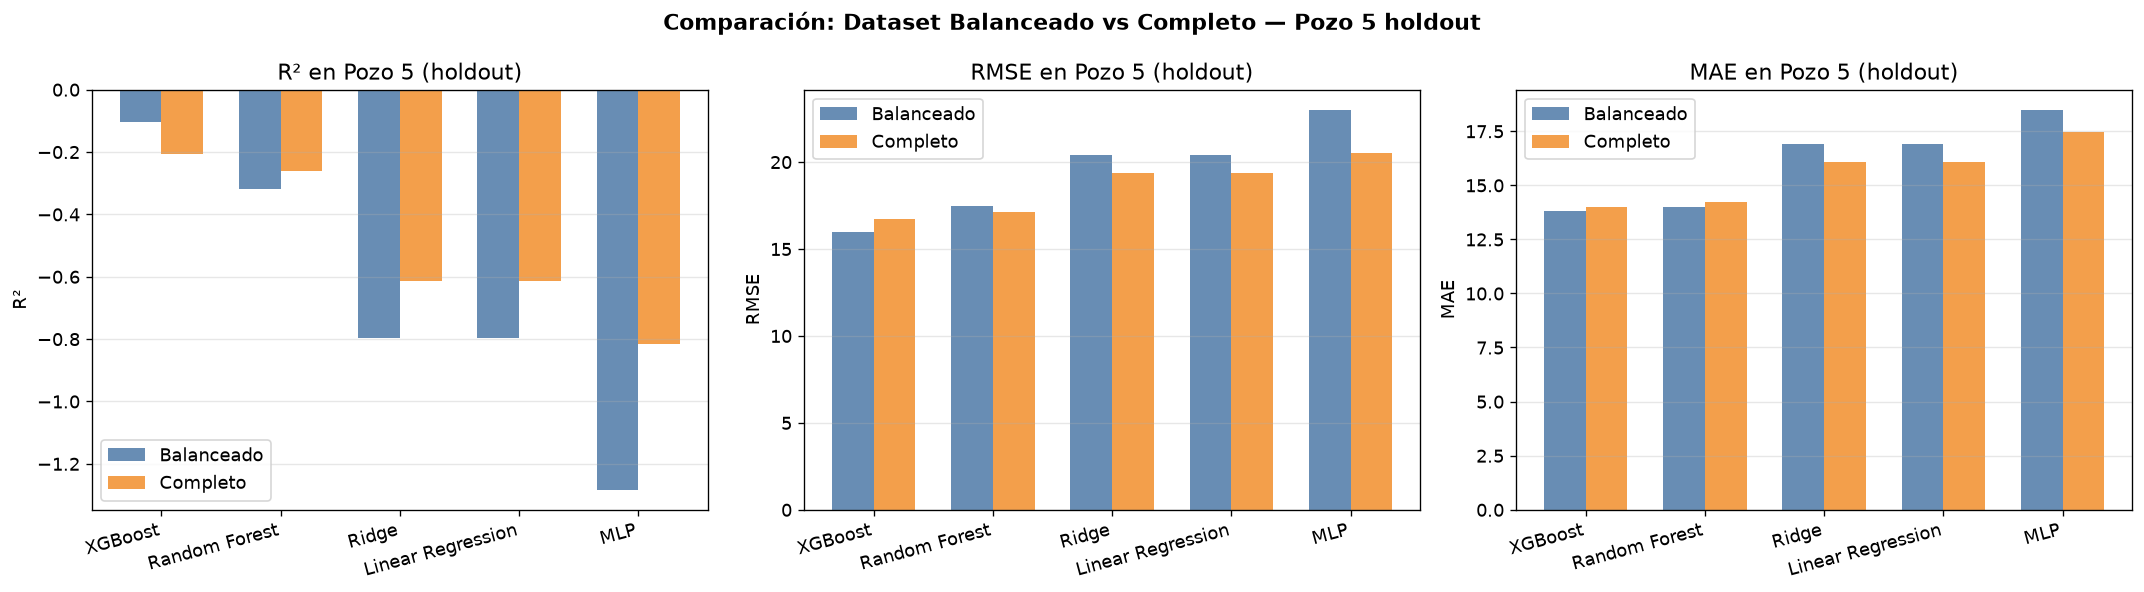

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metricas_comp = [('R²', True), ('RMSE', False), ('MAE', False)]

for ax, (met, higher_better) in zip(axes, metricas_comp):
    x = np.arange(len(comparacion))
    w = 0.35
    bars1 = ax.bar(x - w/2, comparacion[f'{met} (bal)'],  w, label='Balanceado', color='#4e79a7', alpha=0.85)
    bars2 = ax.bar(x + w/2, comparacion[f'{met} (full)'], w, label='Completo',   color='#f28e2b', alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(comparacion['Modelo'], rotation=15, ha='right')
    ax.set_title(f'{met} en Pozo 5 (holdout)')
    ax.set_ylabel(met)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Comparación: Dataset Balanceado vs Completo — Pozo 5 holdout',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---

## Conclusiones


### 1. Los modelos aprenden la física del proceso de perforación

El experimento de split aleatorio 80/20 confirma que existe una relación estadística
aprendible entre los parámetros operativos (WOB, RPM, torque, presión, caudal) y el ROP.
XGBoost alcanzó R²=0.89 con RMSE=4.9 m/h, capturando interacciones no lineales entre
variables que el análisis de correlación univariado del EDA no podía revelar.

### 2. La relación es no lineal — los modelos lineales son insuficientes

Los modelos lineales (Linear Regression, Ridge) se estancan en R²≈0.40 en todas las
evaluaciones. La diferencia de casi 0.50 puntos de R² respecto a XGBoost y Random Forest
indica que la relación entre parámetros de perforación y ROP no puede ser capturada
por una combinación lineal de variables. XGBoost es consistentemente el mejor modelo
en los cinco experimentos realizados.

### 3. La heterogeneidad entre pozos es el límite real del modelo

El LOWO reveló que la media de ROP varía entre 20.7 m/h (Pozo 4) y 51.9 m/h (Pozo 6)
— una diferencia de más del doble. Cuando el modelo entrena en pozos rápidos y predice
pozos lentos sobreestima sistemáticamente, resultando en R² negativos. Este no es un
problema de algoritmo sino una característica del dominio: el ROP base de cada pozo
depende de la formación geológica, que ningún modelo puede inferir sin haberla visto.

### 4. La normalización Z-score por pozo reduce pero no elimina el problema

Normalizar el target por pozo (media=0, desvío=1) antes de entrenar mejoró el R²
de XGBoost de -0.41 a -0.19 en el LOWO. Eliminar el efecto del ROP base reduce
el error sistemático, pero las relaciones entre variables de perforación y ROP
varían entre formaciones de forma que la normalización del target no puede corregir
completamente.

### 5. El Pozo 5 generaliza mejor que el promedio del LOWO

XGBoost obtuvo R²=-0.10 en el holdout del Pozo 5, mejor que su promedio LOWO de -0.19.
Esto es consistente con el perfil de ROP del Pozo 5, cuya distribución es más similar
al conjunto de entrenamiento que la de los pozos más problemáticos (Pozo 3 y Pozo 4).
Confirma que la capacidad predictiva cross-well es función directa de la similitud
entre el pozo de test y los pozos de entrenamiento.

### 6. Memorizar no es generalizar

El contraste entre el split 80/20 (R²=0.89) y el LOWO (R²=-0.19) ilustra
uno de los conceptos centrales en machine learning: métricas altas en validación
no garantizan buena generalización si el split no es representativo del uso real.
El LOWO es la evaluación honesta para este problema — mide exactamente lo que
importa en producción: predecir un pozo que el modelo nunca vio.

### Implicación práctica

Estos modelos son adecuados para **optimización en tiempo real dentro de pozos
conocidos**, donde el modelo puede interpolar dentro de condiciones que ya vio.
Para predicción en pozos nuevos, se recomienda una etapa de calibración inicial
con los primeros metros del pozo antes de confiar en las predicciones del modelo.